# 06 — Real-practice baseline: CKD progression on three horizons (practice d001)

**First model on real practice data.** Input: the three Tomedo training extracts in
`practice_1/` (one row per patient, one file per prediction horizon: **1, 2 and 5 years**;
reference date `stichtag = 2026-07-01`), documented in
`practice_1/CheCKD — CKD Progression Training Dataset.md`.

This is a **single-practice centralized baseline** — no federation anywhere in this notebook.
It is the reference model the pooled, leave-one-practice-out validation will later be compared
against, and it follows the data scientists' modelling guidance to the letter:

1. Three binary labels per file — `label_g3a` / `label_g3b` / `label_g4` (eGFR < 60 / 45 / 30).
   **One model per horizon × threshold**, trained only where the label is not NULL
   (NULL = prevalent case or no eGFR in the outcome window — deliberate, not missing).
2. **All `status_*` and `label_*` columns are excluded from features**, including the other
   thresholds' labels — otherwise we train on the outcome.
3. Features are already NULL-free with fixed clinical imputation constants plus
   `_hat_messung` indicators — **no re-imputation** anywhere below.
4. **Logistic regression with regularisation** as the first baseline (a binary outcome rules
   out plain linear regression, which predicts outside [0, 1]; logistic regression is also the
   only model class this project deploys federated).
5. Report **AUPRC and calibration alongside AUROC** — events are rare, G4 rarest.
6. Within one practice a patient-level random split is valid (one row per patient); we use
   **5-fold cross-validation with out-of-fold (OOF) evaluation** instead of a single 80/20
   split, because with 21–114 events a single test fold of ~4–23 events is too noisy.

Headline design decisions, justified where they are used:

- **Feature selection:** L1-penalised logistic regression (lasso, `saga`), tuned by inner
  cross-validation on AUPRC *inside each training fold* — selection never sees the evaluation
  fold. The L1-selected set is then refit with L2 (ridge), the standard "relaxed lasso", because
  the lab summaries are strongly correlated (`gfr_letzter` / `gfr_min` / `gfr_mittel`).
- **Class weighting:** `class_weight='balanced'` handles the 2–8% prevalence; the resulting
  level shift is corrected by **intercept-only recalibration** on each training fold, which
  leaves all coefficients (and odds ratios) untouched.
- **Known single-practice facts from the documentation:** the UACR block is essentially never
  measured here, and only patients under lab surveillance are labelable — both are measured
  quantitatively below before modelling.

## 1. Setup and configuration

One global seed (`SEED = 42`) drives every split and stochastic step (project reproducibility
rule). Figure styling matches the retreat deck (`retreat_presentation/scripts/make_figures.py`).

In [1]:
import warnings

from sklearn.exceptions import ConvergenceWarning
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize_scalar
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler

SEED = 42
rng_global = np.random.default_rng(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)
# saga lasso paths on small CV folds occasionally hit the iteration cap before the
# coefficient path fully settles; the inner CV scores every candidate C on held-out
# AUPRC regardless, so the occasional cap warning carries no information here.
# Suppressed for readability; nothing else is silenced.
warnings.filterwarnings("ignore", category=ConvergenceWarning)

DATA = Path("../practice_1")
ASSETS = Path("../retreat_presentation/assets")
DOC = DATA / "CheCKD — CKD Progression Training Dataset.md"
# File names verified against each file's constant `horizont_jahre` column:
HORIZON_FILES = {
    1: "20260925_CKD_Dataframe_d001_1year.csv",
    2: "20260925_CKD_Dataframe_d001.csv",
    5: "20260925_CKD_Dataframe_d001_5years.csv",
}

# Columns that may never enter a feature set (documentation, "Columns to exclude").
ID_COLS = ["praxis", "patientid", "stichtag", "cutoff", "horizont_jahre"]
THRESHOLDS = ["g3a", "g3b", "g4"]
# Surveillance features named in the documentation's sensitivity analysis:
SURVEILLANCE = ["gfr_n", "gfr_n_pro_jahr", "kontakte_12m", "kontakte_pro_jahr"]
# Task gate: below this many labelled events a model cannot be estimated defensibly
# (the documentation anticipates this for G4 in one practice).
MIN_LABELLED_EVENTS = 10

# Retreat-deck palette + rcParams, copied from retreat_presentation/scripts/make_figures.py
INK, TEAL, AMBER, RED, GRAY = "#1b4965", "#2a9d8f", "#e9c46a", "#e76f51", "#8d99ae"
plt.rcParams.update({
    "font.size": 13, "axes.edgecolor": "#5c677d", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 13, "xtick.labelsize": 12, "ytick.labelsize": 12,
    "legend.frameon": False, "legend.fontsize": 12, "figure.facecolor": "white",
})

# Readable English display names for figures/tables (fallback: raw column name).
LABEL_EN = {
    "alter_cutoff": "Age at cutoff (y)", "ist_maennlich": "Male sex",
    "beobachtung_tage": "Observation time (d)", "kontakte_12m": "Contacts, last 12 m",
    "kontakte_pro_jahr": "Contacts per year (5 y)",
    "dm": "Diabetes mellitus", "dm_dauer_tage": "Diabetes duration (d)",
    "aht": "Hypertension", "aht_dauer_tage": "Hypertension duration (d)",
    "cvd": "Cardiovascular disease", "khk": "Ischaemic heart disease",
    "herzinsuffizienz": "Heart failure", "vorhofflimmern": "Atrial fibrillation",
    "zerebrovaskulaer": "Cerebrovascular disease", "pavk_atherosklerose": "Atherosclerosis / PAD",
    "n_icd_dreisteller": "Comorbidity burden (n ICD-3)",
    "adipositas": "Obesity", "dyslipidaemie": "Dyslipidaemia",
    "hyperurikaemie_gicht": "Hyperuricaemia / gout", "raucher": "Smoker",
    "anaemie": "Anaemia", "copd": "COPD",
    "akutes_nierenversagen": "Prior acute kidney injury",
    "urolithiasis": "Urolithiasis", "harnwegsinfekt": "Urinary tract infection",
    "hepatopathie": "Hepatopathy", "autoimmun_rheuma": "Autoimmune / rheumatic",
    "ckd_frueh_icd": "Early CKD coded (N18.1–2)",
    "gfr_hat_messung": "eGFR measured", "gfr_n": "eGFR measurements (n)",
    "gfr_n_pro_jahr": "eGFR measurements /y", "gfr_letzter": "Last eGFR",
    "gfr_min": "Min eGFR (5 y)", "gfr_max": "Max eGFR (5 y)", "gfr_mittel": "Mean eGFR (5 y)",
    "gfr_sd": "eGFR spread (sd)", "gfr_tage_seit_letzter": "Days since last eGFR",
    "gfr_spanne_tage": "eGFR observation span (d)",
    "gfr_slope_valide": "eGFR slope valid", "gfr_slope_pro_jahr": "eGFR slope (ml/min/y)",
    "hba1c_hat_messung": "HbA1c measured", "hba1c_n": "HbA1c measurements (n)",
    "hba1c_n_pro_jahr": "HbA1c measurements /y", "hba1c_letzter": "Last HbA1c (%)",
    "hba1c_min": "Min HbA1c", "hba1c_max": "Max HbA1c", "hba1c_mittel": "Mean HbA1c",
    "hba1c_sd": "HbA1c spread (sd)", "hba1c_tage_seit_letzter": "Days since last HbA1c",
    "hba1c_spanne_tage": "HbA1c observation span (d)",
    "hba1c_slope_valide": "HbA1c slope valid", "hba1c_slope_pro_jahr": "HbA1c slope (%/y)",
    "uacr_hat_messung": "UACR measured", "ualb_hat_messung": "Urine albumin measured",
}

def en(name: str) -> str:
    return LABEL_EN.get(name, name)

print(f"pandas {pd.__version__} | seed {SEED}")
print("doc found:", DOC.exists())

pandas 3.0.3 | seed 42
doc found: True


## 2. Load the three extracts

Each file is one horizon (`horizont_jahre`), one practice (`praxis = d001`), one row per
patient. The cohorts differ between horizons because inclusion is evaluated at each horizon's
own cutoff (`stichtag − horizon`).

In [2]:
extracts = {}
for h, fname in HORIZON_FILES.items():
    d = pd.read_csv(DATA / fname)
    assert d["horizont_jahre"].eq(h).all(), f"{fname}: unexpected horizon {d['horizont_jahre'].unique()}"
    assert d["praxis"].nunique() == 1, "expected a single practice per extract"
    extracts[h] = d

overview = pd.DataFrame([{
    "horizon (y)": h, "rows": len(d), "cutoff": d["cutoff"].iloc[0],
    "stichtag": d["stichtag"].iloc[0],
    "age: mean ± sd": f"{d['alter_cutoff'].mean():.1f} ± {d['alter_cutoff'].std():.1f}",
    "male %": 100 * d["ist_maennlich"].mean(),
    "diabetes %": 100 * d["dm"].mean(), "hypertension %": 100 * d["aht"].mean(),
    "CVD %": 100 * d["cvd"].mean(),
} for h, d in extracts.items()]).set_index("horizon (y)")
overview

,rows,cutoff,stichtag,age: mean ± sd,male %,diabetes %,hypertension %,CVD %
horizon (y),,,,,,,,
1,3378,2025-07-01,2026-07-01,52.6 ± 19.0,45.529899,11.308467,38.395500,26.346951
2,3327,2024-07-01,2026-07-01,52.0 ± 18.8,45.326120,10.219417,35.978359,24.977457
5,2640,2021-07-01,2026-07-01,51.4 ± 18.4,45.795455,9.280303,35.606061,22.916667


## 3. Outcome status flow — who is labelable?

Per the documentation these counts belong in the flow diagram of any publication.
**`nicht_bestimmbar`** (no eGFR measured in the outcome window) is the largest category at
every horizon — this is the *verification bias*: the model learns about **patients under lab
surveillance**, not the whole practice list. `praevalent` patients (already below the threshold
at the cutoff) and `unklar` (last value below but unconfirmed) are excluded by the NULL label,
not by us.

In [3]:
rows = []
for h, d in extracts.items():
    for t in THRESHOLDS:
        sc = d[f"status_{t}"].value_counts()
        labelled = int(d[f"label_{t}"].notna().sum())
        events = int(d[f"label_{t}"].sum())
        rows.append({
            "horizon (y)": h, "task": t.upper(),
            "praevalent": int(sc.get("praevalent", 0)),
            "nicht_bestimmbar": int(sc.get("nicht_bestimmbar", 0)),
            "unklar": int(sc.get("unklar", 0)),
            "negativ": int(sc.get("negativ", 0)),
            "positiv": int(sc.get("positiv", 0)),
            "labelled N": labelled, "events": events,
            "event rate": f"{events / labelled:.3f}" if labelled else "—",
        })
status_flow = pd.DataFrame(rows).set_index(["horizon (y)", "task"])
status_flow

praevalent  nicht_bestimmbar  unklar  negativ  positiv  \
horizon (y) task                                                           
1           G3A          292              2099      73      893       21   
            G3B           85              2160      25     1091       17   
            G4            22              2173       6     1177        0   
2           G3A          255              1610      85     1316       61   
            G3B           69              1637      27     1557       37   
            G4            18              1647       5     1653        4   
5           G3A          177               873      75     1401      114   
            G3B           38               877      23     1641       61   
            G4             8               878       5     1737       12   

                  labelled N  events event rate  
horizon (y) task                                 
1           G3A          914      21      0.023  
            G3B         1108      17      0.015  
            G4          1177       0      0.000  
2           G3A         1377      61      0.044  
            G3B         1594      37      0.023  
            G4          1657       4      0.002  
5           G3A         1515     114      0.075  
            G3B         1702      61      0.036  
            G4          1749      12      0.007

**Reading this table:** a G4 event within 1 year did not occur once in this practice; within
2 years it occurred 4 times. Only the 5-year G4 task (12 events) passes the ≥10-event gate, and
even it is reported as **exploratory** — 12 events cannot support a multivariable model
(the classical EPV ≥ 10 rule would allow a single predictor). This scarcity is not a defect of
the pipeline; it is the argument for the federated pooling of practices this project builds.

## 4. Who gets labelled — the surveillance selection, made visible

Comparing the labelable G3a cohort against `nicht_bestimmbar` patients per horizon. If being
measured is driven by clinical concern, the labelled cohort should be older and sicker — and it
is, visibly. Any model trained here describes the **surveillance cohort**; deployment to
unmeasured patients is an extrapolation.

In [4]:
cmp_rows = []
for h, d in extracts.items():
    lab = d.loc[d["label_g3a"].notna()]
    unlab = d.loc[d["status_g3a"] == "nicht_bestimmbar"]
    for grp, g in [("labelled", lab), ("nicht_bestimmbar", unlab)]:
        cmp_rows.append({
            "horizon (y)": h, "group": grp, "N": len(g),
            "age": round(g["alter_cutoff"].mean(), 1),
            "eGFR measured %": round(100 * g["gfr_hat_messung"].mean(), 1),
            "diabetes %": round(100 * g["dm"].mean(), 1),
            "hypertension %": round(100 * g["aht"].mean(), 1),
            "contacts/12m": round(g["kontakte_12m"].mean(), 1),
            "observation (y)": round(g["beobachtung_tage"].mean() / 365.25, 1),
        })
cohort_cmp = pd.DataFrame(cmp_rows)
cohort_cmp

,horizon (y),group,N,age,eGFR measured %,diabetes %,hypertension %,contacts/12m,observation (y)
0,1,labelled,914,56.6,88.7,19.3,52.0,5.5,5.8
1,1,nicht_bestimmbar,2099,46.2,58.4,3.6,23.2,3.6,5.0
2,2,labelled,1377,55.2,86.7,13.5,46.1,5.5,5.0
3,2,nicht_bestimmbar,1610,43.4,44.8,2.4,16.0,2.7,4.1
4,5,labelled,1515,52.7,87.1,9.7,39.7,3.6,2.7
5,5,nicht_bestimmbar,873,41.7,36.9,2.6,14.0,1.4,2.3


## 5. Laboratory coverage — the UACR fact, quantified

`_hat_messung` rates per horizon. The documentation warned that UACR is "almost never stored"
in this practice: measured — the UACR block is present in **≤ 2 of ~3,000 patients**
(0.0–0.07%), urine albumin likewise. HbA1c exists for ~25%, eGFR for ~70%.

Consequence for feature selection: most UACR/urine-albumin columns are **constant within a
horizon** (filled with the neutral constant) and will be removed by the constant-column filter
before training — empirically answering the "should I include the UACR block?" question *for
this practice*. The sensitivity analysis in §10 measures what the block adds where it varies at
all. In pooled data `uacr_hat_messung` would partly act as a practice indicator, as the
documentation warns — not an issue here (one practice), relevant at pooling.

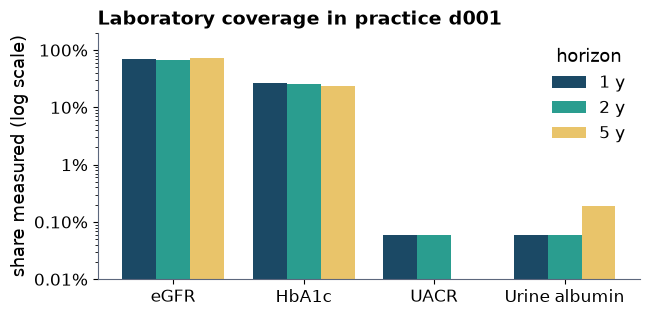

measured share in %:
horizon          1 y    2 y    5 y
eGFR           71.02  67.72  71.67
HbA1c          26.67  25.70  23.26
UACR            0.06   0.06   0.00
Urine albumin   0.06   0.06   0.19


In [5]:
cov = pd.DataFrame({
    h: pd.Series({
        "eGFR": d["gfr_hat_messung"].mean(),
        "HbA1c": d["hba1c_hat_messung"].mean(),
        "UACR": d["uacr_hat_messung"].mean(),
        "Urine albumin": d["ualb_hat_messung"].mean(),
    }) for h, d in extracts.items()
})
cov.columns = pd.Index([f"{h} y" for h in cov.columns], name="horizon")
fig, ax = plt.subplots(figsize=(7, 3.2))
x = np.arange(len(cov.index)); w = 0.26
for i, (h, col) in enumerate([(1, INK), (2, TEAL), (5, AMBER)]):
    ax.bar(x + (i - 1) * w, cov[f"{h} y"], w, color=col, label=f"{h} y")
ax.set_yscale("log"); ax.set_ylim(1e-4, 2)
ax.set_xticks(x); ax.set_xticklabels(cov.index)
ax.set_ylabel("share measured (log scale)")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.2%}" if v < 0.01 else f"{v:.0%}")
ax.legend(title="horizon")
ax.set_title("Laboratory coverage in practice d001")
plt.show()
print("measured share in %:")
print((100 * cov).round(2))

## 6. Feature-space hygiene — what should *not* go into the model

Three screens before any model is fitted (shown on the 2-year G3a task as the example; the
training pipeline applies the same filters **fold-locally** so no evaluation information leaks):

1. **Excluded by contract** — identifiers, run parameters, all `status_*` / `label_*` columns.
2. **Constant / near-constant within the task's labelled cohort** — no variance, no signal.
   This is where most of the UACR and urine-albumin blocks die in this practice (§5), and where
   `ckd_g3plus_icd` goes in the G3a task (constant 0 exactly as the documentation predicts).
3. **Redundant by collinearity** — the lab summaries are strongly internally correlated. L1
   selection handles this by choosing a representative per cluster (seen in §7); the heatmap and
   top-pair table make the structure explicit.

And one screen for *suspicious* strength: a **univariate association screen** (per-feature
AUROC). Features that look "too strong" get a leakage argument or they stay. What we expect on
top: the feature-window eGFR block — legitimate, *kidney function measured before the cutoff
predicting kidney function after it is the entire point of the task*, and the timeline
guarantees no post-cutoff information in any feature.

task 2y-G3A: N=1377, events=61, candidate features=77

constant columns removed (7):
  ckd_g3plus_icd, gfr_anteil_zensiert, uacr_log_sd, uacr_spanne_tage, uacr_anteil_zensiert, uacr_slope_valide, uacr_log_slope_pro_jahr


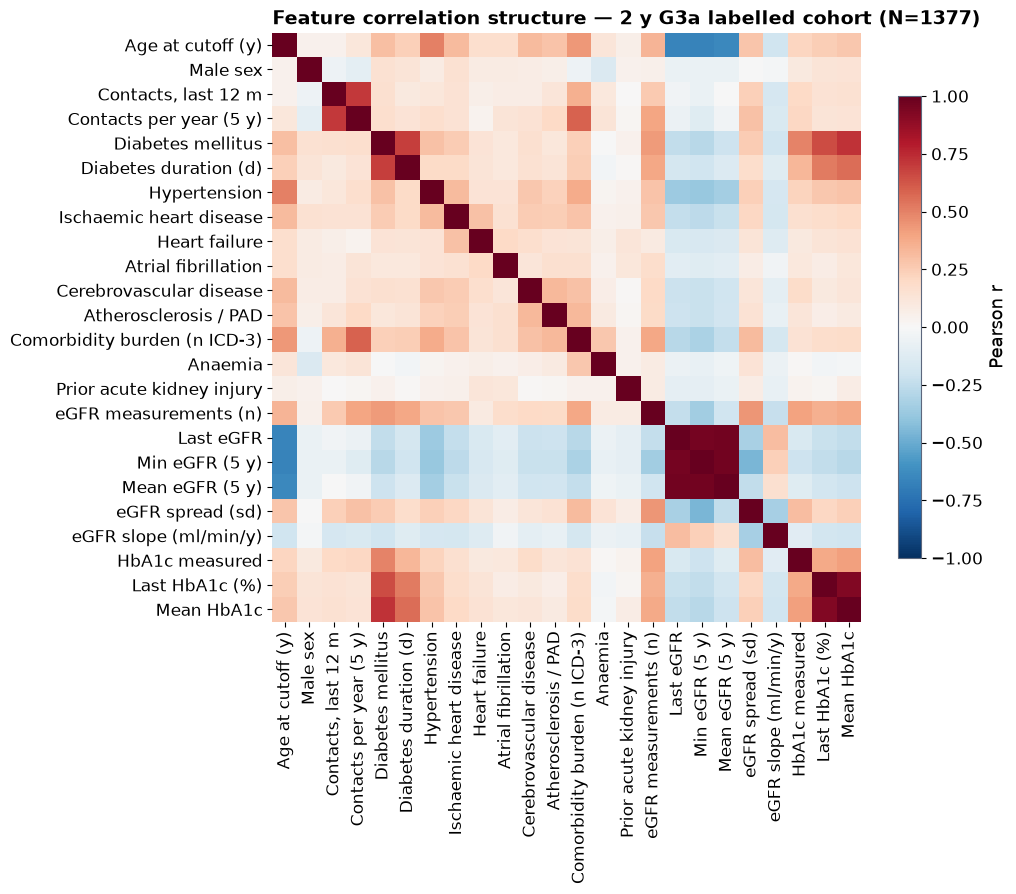

correlated pairs with |r| >= 0.8 (of 70 non-constant features):


,a,b,|r|
1,gfr_n,gfr_n_pro_jahr,1.0
2,uacr_log_letzter,uacr_log_mittel,1.0
3,uacr_log_max,ualb_log_letzter,1.0
4,uacr_log_max,ualb_n,1.0
5,uacr_log_max,ualb_hat_messung,1.0
6,uacr_log_max,uacr_tage_seit_letzter,1.0
7,uacr_log_max,uacr_log_mittel,1.0
8,uacr_log_min,ualb_tage_seit_letzter,1.0
9,uacr_log_min,ualb_log_max,1.0
10,uacr_log_min,ualb_log_mittel,1.0


In [6]:
h0, t0 = 2, "g3a"
d0 = extracts[h0]
sub0 = d0.loc[d0[f"label_{t0}"].notna()]
y0 = sub0[f"label_{t0}"].astype(int).to_numpy()
leak_cols = [c for c in d0.columns if c.startswith(("status_", "label_"))]
feat0 = [c for c in d0.columns if c not in set(ID_COLS) | set(leak_cols)]
assert int(sub0[feat0].isna().sum().sum()) == 0, "feature columns must stay NULL-free"

const0 = [c for c in feat0 if sub0[c].nunique(dropna=False) < 2]
nonconst0 = [c for c in feat0 if c not in const0]
print(f"task 2y-{t0.upper()}: N={len(sub0)}, events={y0.sum()}, candidate features={len(feat0)}")
print(f"\nconstant columns removed ({len(const0)}):")
print(" ", ", ".join(const0))

# Structure: correlation heatmap over a curated clinically legible subset
HEAT_VIZ = [c for c in [
    "alter_cutoff", "ist_maennlich", "kontakte_12m", "kontakte_pro_jahr",
    "dm", "dm_dauer_tage", "aht", "khk", "herzinsuffizienz", "vorhofflimmern",
    "zerebrovaskulaer", "pavk_atherosklerose", "n_icd_dreisteller",
    "anaemie", "akutes_nierenversagen",
    "gfr_n", "gfr_letzter", "gfr_min", "gfr_mittel", "gfr_sd", "gfr_slope_pro_jahr",
    "hba1c_hat_messung", "hba1c_letzter", "hba1c_mittel",
] if c in nonconst0]
C = sub0[HEAT_VIZ].corr()
fig, ax = plt.subplots(figsize=(9.5, 8))
im = ax.imshow(C.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(HEAT_VIZ))); ax.set_xticklabels([en(c) for c in HEAT_VIZ], rotation=90)
ax.set_yticks(range(len(HEAT_VIZ))); ax.set_yticklabels([en(c) for c in HEAT_VIZ])
for s in ax.spines.values(): s.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.75, label="Pearson r")
ax.set_title(f"Feature correlation structure — 2 y G3a labelled cohort (N={len(sub0)})")
plt.show()

# Top absolute-correlation pairs across ALL non-constant features
full_corr = sub0[nonconst0].corr().abs()
iu = np.triu_indices_from(full_corr, k=1)
pairs = (pd.DataFrame({"a": full_corr.index[iu[0]], "b": full_corr.columns[iu[1]],
                       "|r|": full_corr.to_numpy()[iu]})
         .query("`|r|` >= 0.8").sort_values("|r|", ascending=False).reset_index(drop=True))
pairs.index += 1
print(f"correlated pairs with |r| >= 0.8 (of {len(nonconst0)} non-constant features):")
pairs.head(12)

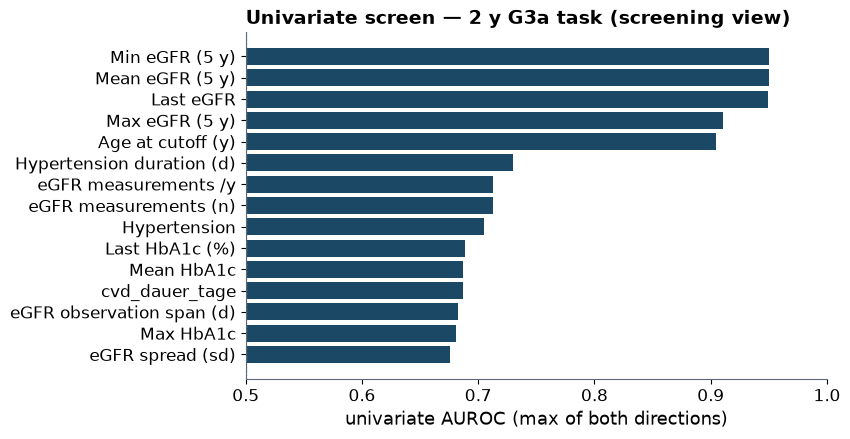

eGFR-block dominance is expected and legitimate (feature window only).


,feature,column,AUROC
0,Min eGFR (5 y),gfr_min,0.950
1,Mean eGFR (5 y),gfr_mittel,0.950
2,Last eGFR,gfr_letzter,0.949
3,Max eGFR (5 y),gfr_max,0.910
4,Age at cutoff (y),alter_cutoff,0.905
5,Hypertension duration (d),aht_dauer_tage,0.730
6,eGFR measurements /y,gfr_n_pro_jahr,0.713
7,eGFR measurements (n),gfr_n,0.713
8,Hypertension,aht,0.705
9,Last HbA1c (%),hba1c_letzter,0.689


In [7]:
# Univariate association screen (screening only — model selection stays fold-local)
uni = []
for c in nonconst0:
    x = sub0[c].to_numpy(dtype=float)
    if np.std(x) == 0: continue
    a = roc_auc_score(y0, x)
    uni.append({"feature": en(c), "column": c, "AUROC": max(a, 1 - a)})
uni = pd.DataFrame(uni).sort_values("AUROC", ascending=False).head(15)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.barh(uni["feature"][::-1], uni["AUROC"][::-1], color=INK)
ax.axvline(0.5, color=GRAY, ls=":", lw=1)
ax.set_xlim(0.5, 1); ax.set_xlabel("univariate AUROC (max of both directions)")
ax.set_title("Univariate screen — 2 y G3a task (screening view)")
plt.show()
print("eGFR-block dominance is expected and legitimate (feature window only).")
uni = uni.reset_index(drop=True)
uni["AUROC"] = uni["AUROC"].round(3)
uni

## 7. The training pipeline

One function per horizon × threshold task, applied identically everywhere below:

```
labelled rows (label not NULL)
  └─ 5-fold stratified split (patient-level; one row per patient so no grouping needed)
       └─ per training fold:
            1. drop columns constant *in that fold*          <- no leak from eval fold
            2. StandardScaler fit *on that fold*             <- documentation: standardise
            3. L1 logistic regression (saga), inner 3-fold CV over C, scoring = AUPRC
               -> selected features (non-zero coefficients)
            4. L2 logistic regression, inner 3-fold CV over C, scoring = AUPRC,
               refit on the L1-selected features  ("relaxed lasso": lasso selects,
               ridge stabilises the correlated lab summaries)
            5. intercept-only recalibration on the training fold
               (class_weight='balanced' shifts the level; the Prentice–Pyke result on
               weighted logistic regression is that slopes — the odds ratios — stay
               consistent, only the intercept needs correction)
       -> out-of-fold prediction for every patient
```

Evaluation is on the pooled OOF predictions: **AUROC, AUPRC (with the event rate as its no-skill
baseline), Brier score, calibration intercept/slope**, all with 1000-sample bootstrap CIs where
meaningful, plus an **OOF permutation-importance** profile (AUPRC drop, 8 repeats, averaged over
folds).

In [8]:
import time
from collections import Counter

CS_L1 = np.logspace(-4, 0.5, 10)   # lasso-strength grid, inner CV picks by AUPRC
CS_L2 = np.logspace(-3, 1, 9)      # ridge-refit grid

def logit(p, eps=1e-6):
    p = np.clip(np.asarray(p, dtype=float), eps, 1 - eps)
    return np.log(p / (1 - p))

def _recal_intercept(y_tr, logit_tr):
    """Intercept-only level correction on the training fold (slopes untouched)."""
    f = lambda b: -np.sum(y_tr * (logit_tr + b) - np.logaddexp(0, logit_tr + b))
    return float(minimize_scalar(f).x)

def _metrics(y, p):
    out = {"AUROC": float(roc_auc_score(y, p)),
           "AUPRC": float(average_precision_score(y, p)),
           "Brier": float(brier_score_loss(y, p)),
           "prevalence": float(np.mean(y))}
    cal = LogisticRegression(penalty=None, solver="lbfgs").fit(logit(p).reshape(-1, 1), y)
    out["cal_intercept"] = float(cal.intercept_[0])
    out["cal_slope"] = float(cal.coef_[0][0])
    return out

def _boot_ci(y, p, fn, B=1000):
    rng = np.random.default_rng(SEED); n = len(y); vals = []
    while len(vals) < B:
        i = rng.integers(0, n, n)
        if y[i].sum() in (0, n):
            continue
        vals.append(float(fn(y[i], p[i])))
    return np.percentile(vals, [2.5, 97.5])

def _select_and_fit(Z, y_tr, n_names):
    """L1/lasso selection (inner CV) -> L2/ridge refit on the selected set."""
    l1 = LogisticRegressionCV(Cs=CS_L1, penalty="l1", solver="saga",
        scoring="average_precision", class_weight="balanced", cv=3,
        max_iter=6000, n_jobs=-1, random_state=SEED).fit(Z, y_tr)
    keep = np.flatnonzero(np.abs(l1.coef_[0]) > 1e-8)
    if keep.size == 0:
        keep = np.arange(n_names)   # lasso empty across its grid -> ridge on all features
    l2 = LogisticRegressionCV(Cs=CS_L2, penalty="l2", solver="lbfgs",
        scoring="average_precision", class_weight="balanced", cv=3,
        max_iter=2000, n_jobs=-1, random_state=SEED).fit(Z[:, keep], y_tr)
    return l1, l2, keep

def fit_task(df, threshold, drop_extra=(), n_splits=5):
    """One horizon x threshold -> nested-selection OOF evaluation (see pipeline above)."""
    label = f"label_{threshold}"
    sub = df.loc[df[label].notna()].copy()
    y = sub[label].astype(int).to_numpy()
    leak = {c for c in df.columns if c.startswith(("status_", "label_"))}
    feats = [c for c in df.columns if c not in set(ID_COLS) | leak | set(drop_extra)]
    assert int(sub[feats].isna().sum().sum()) == 0

    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    oof = np.zeros(len(sub)); folds = []; sel_counter = Counter()
    for k, (tr, te) in enumerate(skf.split(sub[feats], y)):
        Xtr, Xte = sub[feats].iloc[tr], sub[feats].iloc[te]
        nz = [c for c in feats if Xtr[c].nunique() >= 2]          # fold-local constant filter
        sc = StandardScaler().fit(Xtr[nz])                        # fold-local standardisation
        Ztr, Zte = sc.transform(Xtr[nz]), sc.transform(Xte[nz])
        l1, l2, keep = _select_and_fit(Ztr, y[tr], nz)
        d_int = _recal_intercept(y[tr], logit(l2.predict_proba(Ztr[:, keep])[:, 1]))
        oof[te] = 1 / (1 + np.exp(-(logit(l2.predict_proba(Zte[:, keep])[:, 1]) + d_int)))
        sel_counter.update(np.array(nz)[keep].tolist())
        folds.append({"model": l2, "scaler": sc, "nz": nz, "keep": keep, "te": te,
                      "l1_C": float(l1.C_[0]), "l2_C": float(l2.C_[0]),
                      "n_selected": int(len(keep))})
    m = _metrics(y, oof)
    m["AUROC_CI"] = _boot_ci(y, oof, roc_auc_score)
    m["AUPRC_CI"] = _boot_ci(y, oof, average_precision_score)

    # OOF permutation importance: AUPRC drop when one feature is shuffled in the eval fold
    rng = np.random.default_rng(SEED); imp = {}
    for fd in folds:
        yte = y[fd["te"]]
        Zte = fd["scaler"].transform(sub[fd["nz"]].iloc[fd["te"]])
        base = average_precision_score(yte, fd["model"].predict_proba(Zte[:, fd["keep"]])[:, 1])
        for j, c in enumerate(fd["nz"]):
            drops = []
            for _ in range(8):
                Zp = Zte.copy(); Zp[:, j] = rng.permutation(Zp[:, j])
                drops.append(base - average_precision_score(
                    yte, fd["model"].predict_proba(Zp[:, fd["keep"]])[:, 1]))
            imp.setdefault(c, []).append(float(np.mean(drops)))
    return {"horizon_task": threshold, "n": int(len(sub)), "events": int(y.sum()),
            "y": y, "oof": oof, "feats": feats, "folds": folds,
            "sel_counter": sel_counter, "metrics": m,
            "importance": pd.Series({c: float(np.mean(v)) for c, v in imp.items()})
                                .sort_values(ascending=False)}

def fit_final(df, threshold):
    """Reference model fit once on ALL labelled rows (selection pipeline identical).
    ORs + approx. Wald CIs come from an UNPENALISED refit on the L1-selected features;
    the deployed prediction model stays the ridge-shrunk fit (ORs are then conservative)."""
    label = f"label_{threshold}"
    sub = df.loc[df[label].notna()].copy()
    y = sub[label].astype(int).to_numpy()
    leak = {c for c in df.columns if c.startswith(("status_", "label_"))}
    feats = [c for c in df.columns if c not in set(ID_COLS) | leak]
    nz = [c for c in feats if sub[c].nunique() >= 2]
    sc = StandardScaler().fit(sub[nz]); Z = sc.transform(sub[nz])
    l1, l2, keep = _select_and_fit(Z, y, nz)
    sel = [nz[j] for j in keep]
    d_int = _recal_intercept(y, logit(l2.predict_proba(Z[:, keep])[:, 1]))
    Zs = Z[:, keep]
    inf = LogisticRegression(penalty=None, solver="lbfgs", max_iter=2000,
                             class_weight="balanced").fit(Zs, y)
    p = inf.predict_proba(Zs)[:, 1]; W = p * (1 - p)
    H = (Zs * W[:, None]).T @ Zs + 1e-6 * np.eye(len(keep))
    se = np.sqrt(np.diag(np.linalg.inv(H))); z = 1.959964
    # Separation guard: at few events the unpenalised refit on co-selected, strongly
    # correlated lab summaries can separate (|beta| -> inf, ORs meaningless). Detect
    # and fall back to the ridge-shrunk ORs without CIs instead.
    stable = bool(np.max(np.abs(inf.coef_[0])) <= 10 and np.max(se) <= 5)
    if stable:
        or_tab = pd.DataFrame({"feature": sel, "OR": np.exp(inf.coef_[0]),
                               "ci_lo": np.exp(inf.coef_[0] - z * se),
                               "ci_hi": np.exp(inf.coef_[0] + z * se),
                               "approx_ci": True})
    else:
        or_tab = pd.DataFrame({"feature": sel, "OR": np.exp(l2.coef_[0]),
                               "ci_lo": np.nan, "ci_hi": np.nan, "approx_ci": False})
    return {"sub": sub, "y": y, "scaler": sc, "model": l2, "keep": keep, "sel": sel,
            "intercept_shift": d_int, "or_table": or_tab, "or_stable": stable,
            "l1_C": float(l1.C_[0]), "l2_C": float(l2.C_[0])}

print("pipeline defined.")

pipeline defined.


## 8. The three horizon models — G3a (eGFR < 60) as the primary endpoint

The documentation: *"Train one model per horizon and threshold."* The user-facing deliverable is
three models, one per horizon; G3a is the clinically primary task (new confirmed CKD G3a+), and
it is where this single practice has enough events (§9 trains every feasible horizon × threshold
combination; §3's flow table shows why G4 mostly cannot be trained on one practice).

All CIs are 95% bootstrap over patients on the OOF predictions.

In [9]:
primary = {}
for h, d in extracts.items():
    t0 = time.time()
    primary[h] = fit_task(d, "g3a")
    r = primary[h]; m = r["metrics"]
    print(f"g3a {h}y: N={r['n']}, events={r['events']}  "
          f"AUROC={m['AUROC']:.3f}  AUPRC={m['AUPRC']:.3f}  ({time.time() - t0:.0f}s)")

def fmt_ci(v, ci):
    return f"{v:.3f} [{ci[0]:.3f}–{ci[1]:.3f}]"

rows = []
for h, r in primary.items():
    m = r["metrics"]
    rows.append({
        "horizon": f"{h} y", "labelled N": r["n"], "events": r["events"],
        "median features/fold": int(np.median([f["n_selected"] for f in r["folds"]])),
        "AUROC [95% CI]": fmt_ci(m["AUROC"], m["AUROC_CI"]),
        "AUPRC [95% CI]": fmt_ci(m["AUPRC"], m["AUPRC_CI"]),
        "AUPRC baseline": f"{m['prevalence']:.3f}",
        "Brier": f"{m['Brier']:.4f}",
        "cal. intercept": f"{m['cal_intercept']:+.2f}",
        "cal. slope": f"{m['cal_slope']:.2f}",
    })
primary_table = pd.DataFrame(rows).set_index("horizon")
primary_table

g3a 1y: N=914, events=21  AUROC=0.887  AUPRC=0.394  (15s)


g3a 2y: N=1377, events=61  AUROC=0.933  AUPRC=0.466  (19s)


g3a 5y: N=1515, events=114  AUROC=0.950  AUPRC=0.624  (12s)


,labelled N,events,median features/fold,AUROC [95% CI],AUPRC [95% CI],AUPRC baseline,Brier,cal. intercept,cal. slope
horizon,,,,,,,,,
1 y,914,21,8,0.887 [0.760–0.980],0.394 [0.231–0.663],0.023,0.0174,-1.18,0.43
2 y,1377,61,5,0.933 [0.889–0.968],0.466 [0.357–0.594],0.044,0.0323,+0.68,1.32
5 y,1515,114,5,0.950 [0.934–0.965],0.624 [0.532–0.726],0.075,0.0408,-0.05,0.98


**How to read this.** The 1-year model has only 21 events — its OOF discrimination is a wide-
interval estimate, not a precise one. The AUPRC baseline row is the event rate: everything above
it is learned signal. Calibration intercept ≈ 0 / slope ≈ 1 is ideal; slope < 1 means the model's
risk spread is wider than observed (mild over-confidence), slope > 1 the opposite. The
intercept-only recalibration keeps intercepts close to 0 by construction on training folds; the
OOF values above are the honest check.

## 9. Calibration check (OOF)

Quantile-binned observed event rate vs mean predicted risk per model; the diagonal is perfect
calibration. At these event counts the top bins carry a handful of events — read with the
binomial error bars.

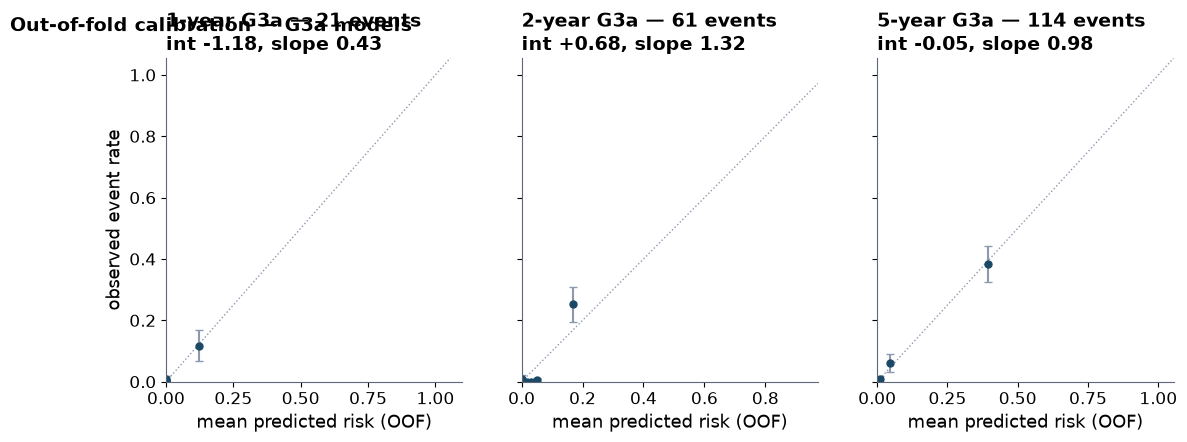

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
for ax, (h, r) in zip(axes, primary.items()):
    y, p = r["y"], r["oof"]
    qs = np.quantile(p, np.linspace(0, 1, 7)); qs[0], qs[-1] = 0.0, 1.0
    bins = np.unique(qs)
    ix = np.clip(np.searchsorted(bins, p, side="right") - 1, 0, len(bins) - 2)
    for i in range(len(bins) - 1):
        m_ = ix == i
        if m_.sum() == 0: continue
        obs, n = y[m_].mean(), m_.sum()
        se = np.sqrt(obs * (1 - obs) / n)
        ax.errorbar(p[m_].mean(), obs, yerr=1.96 * se, fmt="o", color=INK,
                    ecolor=GRAY, capsize=3, ms=5)
    lim = max(p.max() * 1.1, y.mean() * 3)
    ax.plot([0, lim], [0, lim], ls=":", color=GRAY, lw=1)
    m = r["metrics"]
    ax.set_title(f"{h}-year G3a — {r['events']} events\n"
                 f"int {m['cal_intercept']:+.2f}, slope {m['cal_slope']:.2f}")
    ax.set_xlabel("mean predicted risk (OOF)"); ax.set_xlim(0, lim); ax.set_ylim(0, lim)
axes[0].set_ylabel("observed event rate")
fig.suptitle("Out-of-fold calibration — G3a models", x=0.005, ha="left",
             fontsize=14, fontweight="bold")
plt.show()

## 9. All thresholds × all horizons — what one practice can and cannot estimate

The documentation's full grid is 3 thresholds × 3 horizons. A task is trained when it has
≥ 10 labelled events; below that the honest answer is *not estimable in a single practice*.
G3a rows reuse §8. Estimates with < 20 events are tagged **exploratory** — report them only to
make the case for pooling, never as validated performance.

In [11]:
sweep_rows = []; sweep = {}
for h, d in extracts.items():
    for t in THRESHOLDS:
        lab = d[f"label_{t}"]
        n_lab, n_ev = int(lab.notna().sum()), int(lab.sum(skipna=True))
        base = {"horizon": f"{h} y", "task": t.upper(), "labelled N": n_lab, "events": n_ev}
        if n_ev < MIN_LABELLED_EVENTS:
            sweep_rows.append(base | {"model": f"SKIPPED (< {MIN_LABELLED_EVENTS} events)",
            "AUROC [95% CI]": "—", "AUPRC [95% CI]": "—",
            "AUPRC baseline": "—", "Brier": "—", "cal. slope": "—"})
            print(f"{t.upper()} {h}y: skipped, {n_ev} events")
            continue
        t0 = time.time()
        r = primary[h] if t == "g3a" else fit_task(d, t)
        sweep[(h, t)] = r
        m = r["metrics"]
        tag = "  (exploratory — very few events)" if n_ev < 20 else ""
        sweep_rows.append(base | {
            "model": "trained" + tag,
            "AUROC [95% CI]": fmt_ci(m["AUROC"], m["AUROC_CI"]),
            "AUPRC [95% CI]": fmt_ci(m["AUPRC"], m["AUPRC_CI"]),
            "AUPRC baseline": f"{m['prevalence']:.3f}",
            "Brier": f"{m['Brier']:.4f}",
            "cal. slope": f"{m['cal_slope']:.2f}",
        })
        print(f"{t.upper()} {h}y: AUROC={m['AUROC']:.3f} AUPRC={m['AUPRC']:.3f}{tag}  ({time.time()-t0:.0f}s)")
sweep_table = pd.DataFrame(sweep_rows).set_index(["horizon", "task"])
sweep_table

G3A 1y: AUROC=0.887 AUPRC=0.394  (0s)


G3B 1y: AUROC=0.975 AUPRC=0.476  (exploratory — very few events)  (14s)
G4 1y: skipped, 0 events
G3A 2y: AUROC=0.933 AUPRC=0.466  (0s)


G3B 2y: AUROC=0.943 AUPRC=0.381  (23s)
G4 2y: skipped, 4 events
G3A 5y: AUROC=0.950 AUPRC=0.624  (0s)


G3B 5y: AUROC=0.924 AUPRC=0.363  (14s)


G4 5y: AUROC=0.696 AUPRC=0.112  (exploratory — very few events)  (32s)


labelled N  events                                     model  \
horizon task                                                                 
1 y     G3A          914      21                                   trained   
        G3B         1108      17  trained  (exploratory — very few events)   
        G4          1177       0                     SKIPPED (< 10 events)   
2 y     G3A         1377      61                                   trained   
        G3B         1594      37                                   trained   
        G4          1657       4                     SKIPPED (< 10 events)   
5 y     G3A         1515     114                                   trained   
        G3B         1702      61                                   trained   
        G4          1749      12  trained  (exploratory — very few events)   

                   AUROC [95% CI]       AUPRC [95% CI] AUPRC baseline   Brier  \
horizon task                                                                    
1 y     G3A   0.887 [0.760–0.980]  0.394 [0.231–0.663]          0.023  0.0174   
        G3B   0.975 [0.950–0.992]  0.476 [0.261–0.710]          0.015  0.0116   
        G4                      —                    —              —       —   
2 y     G3A   0.933 [0.889–0.968]  0.466 [0.357–0.594]          0.044  0.0323   
        G3B   0.943 [0.887–0.979]  0.381 [0.263–0.547]          0.023  0.0178   
        G4                      —                    —              —       —   
5 y     G3A   0.950 [0.934–0.965]  0.624 [0.532–0.726]          0.075  0.0408   
        G3B   0.924 [0.883–0.956]  0.363 [0.261–0.487]          0.036  0.0289   
        G4    0.696 [0.495–0.888]  0.112 [0.027–0.295]          0.007  0.0071   

             cal. slope  
horizon task             
1 y     G3A        0.43  
        G3B        0.44  
        G4            —  
2 y     G3A        1.32  
        G3B        0.83  
        G4            —  
5 y     G3A        0.98  
        G3B        0.99  
        G4         0.13

G4 is effectively **untrainable in one practice** at 1–2 years (0 and 4 events) and only
exploratory at 5 years. That *is* the federated-learning argument in miniature: the clinically
hardest endpoint is exactly the one a single practice cannot learn alone. The documentation's
KFRE comparator (G4 only, eGFR < 60 subset) needs an evaluable event count as well, so it joins
the pooled-data work plan rather than this single-practice baseline.

## 10. Sensitivity analyses — which blocks actually carry the signal

The documentation names both of these; they answer *"which variables shouldn't I add?"* directly
on the primary G3a tasks:

1. **– surveillance features** (`gfr_n`, `gfr_n_pro_jahr`, `kontakte_12m`, `kontakte_pro_jahr`):
   how much of the signal is *care intensity* (the physician's concern) rather than biology?
2. **– UACR block**: with ≤ 2 measured patients the block is essentially constants plus an
   indicator; if performance is unchanged, UACR adds nothing in this practice (and in pooled data
   `uacr_hat_messung` should be audited as a practice indicator).

**Observed answer (fixed seed, deterministic):** neither block carries anything here. The
surveillance features are never chosen by the lasso at 2 and 5 years (Δ = 0.000), and removing
them at 1 year slightly *helps* (ΔAUROC +0.067) — on 21 events, fewer candidate features mean
less selection variance; the biology (eGFR block, age) is what survives. The UACR block is a
no-op everywhere (|Δ| ≤ 0.009), as §5's coverage rates predict. So for *this practice* the
defensible model is eGFR summaries + age + vascular/diabetes history + comorbidity flags —
exactly what the lasso keeps selecting.

In [12]:
uacr_cols = [c for c in extracts[1].columns if c.startswith("uacr_")]
print(f"UACR block = {len(uacr_cols)} columns")
sens_rows = []
for h, d in extracts.items():
    fm = primary[h]["metrics"]
    for name, drop in [("– surveillance features", SURVEILLANCE), ("– UACR block", uacr_cols)]:
        t0 = time.time()
        r = fit_task(d, "g3a", drop_extra=drop); m = r["metrics"]
        sens_rows.append({
            "horizon": f"{h} y", "model": name,
            "AUROC": f"{m['AUROC']:.3f} [{m['AUROC_CI'][0]:.3f}–{m['AUROC_CI'][1]:.3f}]",
            "Δ AUROC vs full": f"{m['AUROC'] - fm['AUROC']:+.3f}",
            "AUPRC": f"{m['AUPRC']:.3f} [{m['AUPRC_CI'][0]:.3f}–{m['AUPRC_CI'][1]:.3f}]",
            "Δ AUPRC vs full": f"{m['AUPRC'] - fm['AUPRC']:+.3f}",
        })
        print(f"{h}y {name}: AUROC {m['AUROC']:.3f} (Δ {m['AUROC'] - fm['AUROC']:+.3f}), "
              f"AUPRC {m['AUPRC']:.3f} (Δ {m['AUPRC'] - fm['AUPRC']:+.3f})  ({time.time()-t0:.0f}s)")
sens_table = pd.DataFrame(sens_rows).set_index(["horizon", "model"])
sens_table

UACR block = 13 columns


1y – surveillance features: AUROC 0.955 (Δ +0.067), AUPRC 0.420 (Δ +0.026)  (13s)


1y – UACR block: AUROC 0.878 (Δ -0.009), AUPRC 0.394 (Δ -0.000)  (11s)


2y – surveillance features: AUROC 0.933 (Δ +0.000), AUPRC 0.466 (Δ +0.000)  (15s)


2y – UACR block: AUROC 0.933 (Δ +0.000), AUPRC 0.466 (Δ +0.000)  (18s)


5y – surveillance features: AUROC 0.950 (Δ +0.000), AUPRC 0.624 (Δ +0.000)  (12s)


5y – UACR block: AUROC 0.950 (Δ +0.000), AUPRC 0.624 (Δ +0.000)  (12s)


AUROC Δ AUROC vs full  \
horizon model                                                          
1 y     – surveillance features  0.955 [0.923–0.982]          +0.067   
        – UACR block             0.878 [0.758–0.976]          -0.009   
2 y     – surveillance features  0.933 [0.889–0.968]          +0.000   
        – UACR block             0.933 [0.889–0.968]          +0.000   
5 y     – surveillance features  0.950 [0.934–0.965]          +0.000   
        – UACR block             0.950 [0.934–0.965]          +0.000   

                                               AUPRC Δ AUPRC vs full  
horizon model                                                         
1 y     – surveillance features  0.420 [0.252–0.684]          +0.026  
        – UACR block             0.394 [0.217–0.662]          -0.000  
2 y     – surveillance features  0.466 [0.357–0.594]          +0.000  
        – UACR block             0.466 [0.357–0.594]          +0.000  
5 y     – surveillance features  0.624 [0.532–0.726]          +0.000  
        – UACR block             0.624 [0.532–0.726]          +0.000

## 11. Final per-horizon models — feature selection outcome and odds ratios

For reporting: the identical selection pipeline fit once on **all** labelled rows per horizon.
Odds ratios are *per 1 SD* of each standardised feature, from an unpenalised refit on the
L1-selected features (the deployed prediction model is ridge-shrunk, so its ORs would be
conservative); CIs are approximate Wald intervals — with 21–114 events treat them as
indications, not proof. "Selected in n/5 folds" is the stability of each feature's selection
during the §8 cross-validation — the most honest importance statement available at this size.
If the unpenalised refit separates at a small event count, the table flags it and shows
the ridge-shrunk ORs without CIs instead.

In [13]:
finals = {}
for h, d in extracts.items():
    finals[h] = fit_final(d, "g3a")
    f = finals[h]; frq = primary[h]["sel_counter"]
    tab = (f["or_table"]
           .assign(rank=lambda t: np.log(t["OR"]).abs())
           .sort_values("rank", ascending=False).drop(columns="rank"))
    tab["selected in folds"] = [f"{frq.get(c, 0)}/5" for c in tab["feature"]]
    tab["feature"] = tab["feature"].map(en)
    if f["or_stable"]:
        tab["OR [approx. 95% CI]"] = [f"{o:.2f} [{lo:.2f}–{hi:.2f}]"
            for o, lo, hi in zip(tab["OR"], tab["ci_lo"], tab["ci_hi"])]
    else:
        tab["OR [approx. 95% CI]"] = [f"{o:.2f} (ridge-shrunk; refit unstable)"
            for o in tab["OR"]]
        print("NOTE: unpenalised refit separated at this event count -> ridge-shrunk "
              "ORs shown without Wald CIs; this horizon has too few events for "
              "unpenalised inference on the selected set.")
    print(f"── {h}-year G3a model: {len(f['sel'])} features "
          f"(lasso C={f['l1_C']:.3g} -> ridge C={f['l2_C']:.3g}, "
          f"intercept recalibration {f['intercept_shift']:+.2f})")
    display(tab[["feature", "OR [approx. 95% CI]", "selected in folds"]].reset_index(drop=True))

NOTE: unpenalised refit separated at this event count -> ridge-shrunk ORs shown without Wald CIs; this horizon has too few events for unpenalised inference on the selected set.
── 1-year G3a model: 12 features (lasso C=0.0316 -> ridge C=0.0316, intercept recalibration -3.12)


,feature,OR [approx. 95% CI],selected in folds
0,Mean eGFR (5 y),0.35 (ridge-shrunk; refit unstable),5/5
1,Last eGFR,0.38 (ridge-shrunk; refit unstable),5/5
2,Age at cutoff (y),1.92 (ridge-shrunk; refit unstable),3/5
3,Heart failure,1.36 (ridge-shrunk; refit unstable),3/5
4,Early CKD coded (N18.1–2),1.35 (ridge-shrunk; refit unstable),5/5
5,Anaemia,1.33 (ridge-shrunk; refit unstable),3/5
6,Cerebrovascular disease,1.31 (ridge-shrunk; refit unstable),5/5
7,"Contacts, last 12 m",1.17 (ridge-shrunk; refit unstable),1/5
8,Diabetes duration (d),1.14 (ridge-shrunk; refit unstable),3/5
9,Atherosclerosis / PAD,1.12 (ridge-shrunk; refit unstable),1/5


── 2-year G3a model: 6 features (lasso C=0.01 -> ridge C=0.01, intercept recalibration -2.66)


,feature,OR [approx. 95% CI],selected in folds
0,Mean eGFR (5 y),0.14 [0.06–0.31],5/5
1,Last eGFR,0.44 [0.21–0.96],5/5
2,Age at cutoff (y),2.21 [1.56–3.12],3/5
3,Atherosclerosis / PAD,1.85 [1.55–2.21],4/5
4,Diabetes duration (d),1.15 [0.95–1.39],2/5
5,Min eGFR (5 y),1.00 [0.41–2.44],5/5


── 5-year G3a model: 6 features (lasso C=0.01 -> ridge C=0.0316, intercept recalibration -2.37)


,feature,OR [approx. 95% CI],selected in folds
0,Age at cutoff (y),5.42 [4.09–7.17],5/5
1,Mean eGFR (5 y),0.39 [0.19–0.83],4/5
2,Last eGFR,0.60 [0.36–1.01],5/5
3,Min eGFR (5 y),0.61 [0.36–1.04],4/5
4,Ischaemic heart disease,1.27 [1.09–1.49],3/5
5,Atherosclerosis / PAD,1.26 [1.08–1.48],3/5


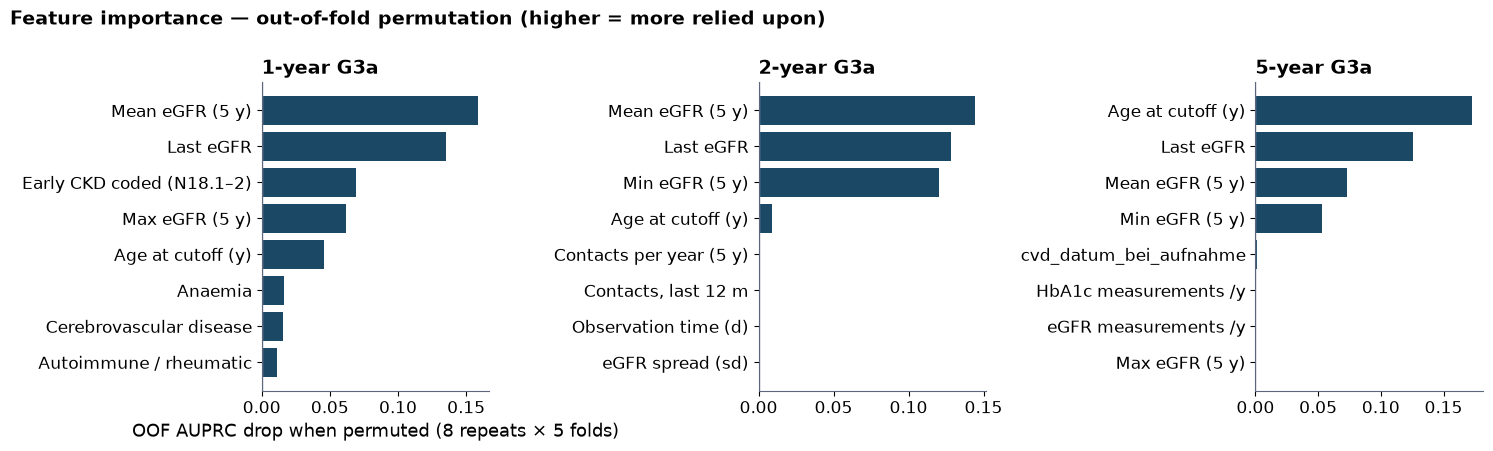

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharex=False)
for ax, (h, r) in zip(axes, primary.items()):
    top = r["importance"].head(8).iloc[::-1]
    ax.barh([en(c) for c in top.index], top.to_numpy(), color=INK)
    ax.axvline(0, color=GRAY, lw=1)
    ax.set_title(f"{h}-year G3a")
axes[0].set_xlabel("OOF AUPRC drop when permuted (8 repeats × 5 folds)")
fig.suptitle("Feature importance — out-of-fold permutation (higher = more relied upon)",
             x=0.005, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

## 12. Figure for the retreat deck

One self-explanatory composite: **A** — what the practice gives us per horizon (labelled
patients + confirmed G3a event rate), **B** — out-of-fold discrimination and precision with 95%
CIs (dotted marks = no-skill AUPRC baseline), **C** — what drives 2-year risk (standardised ORs,
log scale). Saved to `retreat_presentation/assets/fig09_real_practice_progression.png` at
200 dpi in the deck palette, ready to drop into `FLIP-IT_retreat_deck_v4.pptx`.

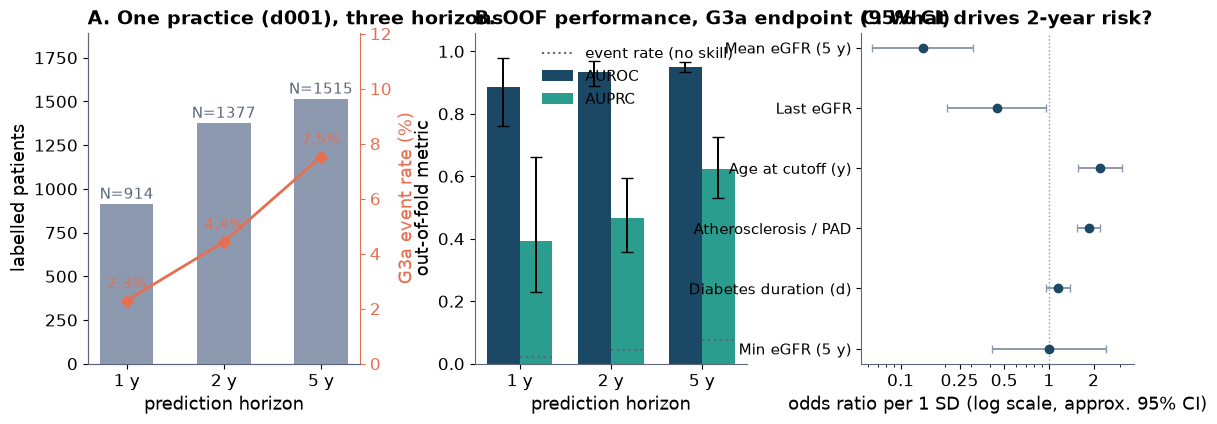

wrote /Users/andtai/Documents/IKIM:Lamarr/FL CKD Flower/retreat_presentation/assets/fig09_real_practice_progression.png


In [15]:
hs = [1, 2, 5]
ns = [primary[h]["n"] for h in hs]
prevs = [primary[h]["metrics"]["prevalence"] for h in hs]
au = [primary[h]["metrics"]["AUROC"] for h in hs]
auci = [primary[h]["metrics"]["AUROC_CI"] for h in hs]
ap = [primary[h]["metrics"]["AUPRC"] for h in hs]
apci = [primary[h]["metrics"]["AUPRC_CI"] for h in hs]

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.3))
fig.subplots_adjust(wspace=0.42)

# Panel A — cohort and event rate per horizon
axA = axes[0]
x = np.arange(3)
bars = axA.bar(x, ns, width=0.55, color=GRAY)
for b, n in zip(bars, ns):
    axA.text(b.get_x() + b.get_width() / 2, n + 30, f"N={n}", ha="center",
             fontsize=11, color="#5c677d")
axA.set_ylim(0, max(ns) * 1.25)
axA.set_ylabel("labelled patients")
axA.set_xticks(x); axA.set_xticklabels([f"{h} y" for h in hs])
axA.set_xlabel("prediction horizon")
axA2 = axA.twinx()
axA2.spines["right"].set_visible(True); axA2.spines["right"].set_color(RED)
axA2.plot(x, [100 * p for p in prevs], "D-", color=RED, lw=2, ms=6,
          label="confirmed G3a event rate")
for xi, p in zip(x, prevs):
    axA2.annotate(f"{100 * p:.1f}%", (xi, 100 * p), textcoords="offset points",
                  xytext=(0, 9), ha="center", color=RED, fontsize=11)
axA2.set_ylim(0, 100 * max(prevs) * 1.6)
axA2.set_ylabel("G3a event rate (%)", color=RED)
axA2.tick_params(axis="y", colors=RED)
axA.set_title("A. One practice (d001), three horizons")

# Panel B — discrimination + precision with CIs
axB = axes[1]
w = 0.36
axB.bar(x - w / 2, au, w, color=INK, label="AUROC",
        yerr=([max(a - c[0], 0) for a, c in zip(au, auci)],
              [c[1] - a for a, c in zip(au, auci)]), capsize=4, error_kw={"lw": 1.4})
axB.bar(x + w / 2, ap, w, color=TEAL, label="AUPRC",
        yerr=([max(a - c[0], 0) for a, c in zip(ap, apci)],
              [c[1] - a for a, c in zip(ap, apci)]), capsize=4, error_kw={"lw": 1.4})
for xi, pv in zip(x, prevs):
    axB.plot([xi + w / 2 - w / 2, xi + w / 2 + w / 2], [pv, pv], ls=":",
             color="#5c677d", lw=1.6)
axB.plot([], [], ls=":", color="#5c677d", label="event rate (no skill)")
axB.set_xticks(x); axB.set_xticklabels([f"{h} y" for h in hs])
axB.set_ylim(0, 1.06); axB.set_ylabel("out-of-fold metric")
axB.set_xlabel("prediction horizon")
axB.set_title("B. OOF performance, G3a endpoint (95% CI)")
axB.legend(loc="upper right", fontsize=11)

# Panel C — driver profile of the 2-year model
axC = axes[2]
ot = (finals[2]["or_table"].assign(rank=lambda t: np.log(t["OR"]).abs())
      .sort_values("rank", ascending=False).head(8).iloc[::-1])
assert bool(finals[2]["or_stable"]) and ot[["ci_lo", "ci_hi"]].notna().all().all(), \
    "panel C needs the stable unpenalised 2y refit"
ypos = np.arange(len(ot))
axC.errorbar(ot["OR"], ypos,
             xerr=[np.clip(ot["OR"] - ot["ci_lo"], 1e-6, None), ot["ci_hi"] - ot["OR"]],
             fmt="o", ms=6, color=INK, ecolor=GRAY, capsize=3, lw=1.4)
axC.axvline(1, color=GRAY, ls=":", lw=1)
axC.set_xscale("log")
axC.set_yticks(ypos); axC.set_yticklabels([en(f) for f in ot["feature"]], fontsize=11)
lo, hi = min(ot["ci_lo"].min(), ot["OR"].min(), 0.8), max(ot["ci_hi"].max(), ot["OR"].max(), 1.3)
axC.set_xlim(lo * 0.85, hi * 1.2)
ticks = [t for t in [0.1, 0.25, 0.5, 1, 2, 4, 10] if lo * 0.85 <= t <= hi * 1.2]
axC.set_xticks(ticks); axC.set_xticklabels([f"{t:g}" for t in ticks])
axC.set_xlabel("odds ratio per 1 SD (log scale, approx. 95% CI)")
axC.set_title("C. What drives 2-year risk?")

out_png = ASSETS / "fig09_real_practice_progression.png"
fig.savefig(out_png, dpi=200, bbox_inches="tight")
plt.show()
print("wrote", out_png.resolve())

## 13. Summary and limitations

**Headline.** *(numbers verified against the executed outputs above)*

- **Three G3a horizon models** (labelled N = 914 / 1,377 / 1,515; events 21 / 61 / 114 for
  1 / 2 / 5 y), OOF AUROC **0.887 / 0.933 / 0.950**; OOF AUPRC **0.394 / 0.466 / 0.624** against
  event-rate baselines of 0.023 / 0.044 / 0.075 — roughly 8–17× the no-skill precision.
- **Calibration** is near-ideal for the 5-year model (intercept −0.05, slope 0.98) and
  serviceable at 2 years (slope 1.32); the 1-year model is over-confident (slope 0.43) on OOF —
  21 events cannot pin down a risk level. Present the 1-year model as a demonstrator, not a
  clinical risk score.
- **Driver profile is stable and clinical**: the feature-window eGFR block (mean / last / min)
  plus age dominate every horizon (2-year model: mean eGFR OR 0.14 per SD, last eGFR 0.44,
  age OR 2.21 per SD, atherosclerosis/PAD OR 1.85); the eGFR features are selected in 5/5 folds.
  This is kidney function predicting kidney function on a clean timeline — signal, not leakage.
- **Full threshold sweep:** G3b trains at all horizons (AUROC 0.975 / 0.943 / 0.924; 1 y
  exploratory). G4 is not trainable from one practice at 1–2 years (0 / 4 events, skipped) and
  only exploratory at 5 years (12 events, AUROC 0.696 with a CI spanning 0.50).
- **Sensitivity analyses:** dropping the surveillance block costs nothing (2 y / 5 y identical;
  1 y marginally *improves* — fewer degrees of freedom on 21 events), and dropping the UACR
  block changes nothing anywhere. Neither block carries signal in this practice at this size.

**Design facts to restate in any talk or paper.**

1. This is a **single centralized practice** (d001): no federation, no pooling — the reference
   baseline for the later leave-one-practice-out validation.
2. The labelled cohort is a **surveillance cohort** by construction (§4): predictions apply to
   patients who get eGFR measured, not the whole practice list (verification bias; survivorship
   bias also documented: patients who died in the outcome window are absent from the extract).
3. **G4 is not learnable from one practice** (0 / 4 / 12 events at 1 / 2 / 5 years) — the
   quantitative case for federated pooling. KFRE comparison goes on the pooled-data plan.
4. The **UACR block carries nothing here** (≤ 2 measured patients, constants filtered, §10);
   at pooling, `uacr_hat_messung` must be audited as a practice indicator.
5. Events too few for per-sex fairness evaluation at useful precision — the T2.5 bias analysis
   (demographic parity, equal opportunity, equalized odds, calibration by sex) also waits for
   pooling; the feature (`ist_maennlich`) and the metric code (`task.fairness_metrics`) exist.

**Next steps once practices pool:** leave-one-practice-out validation grouped by `praxis`
(documentation), grouped-by-`patientid` splits if reference dates are ever stacked, KFRE
benchmark for the G4 task on the eGFR < 60 subset, and the full fairness battery.